In [1]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
#leer archivos

from pathlib import Path

# Localizar la raíz del proyecto
PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError("No se encontró la carpeta data/processed del proyecto.")

DATA_DIR = PROJECT_DIR / "data" / "processed"

# Cargar conjuntos procesados por KNIME
train = pd.read_csv(DATA_DIR / "ghi_multisitio_entrenamiento.csv")
validacion = pd.read_csv(DATA_DIR / "ghi_multisitio_validacion.csv")
test = pd.read_csv(DATA_DIR / "ghi_multisitio_prueba.csv")

print("Entrenamiento:", train.shape)
print("Validación:", validacion.shape)
print("Prueba:", test.shape)


Entrenamiento: (262944, 16)
Validación: (52560, 16)
Prueba: (25992, 16)


In [3]:
#convertir fecha
for df in [train, validacion, test]:
    df["fecha_hora"] = pd.to_datetime(df["fecha_hora"])

# Modelo Base

In [4]:
#definir variable objetivo
target = "ghi_t1"

In [5]:
#usaremos solamente ghi
#¿Qué tan bien puede pronosticarse la próxima hora
#utilizando solamente la radiación actual?
features_base = ["ghi"]

In [6]:
#preparar datos
X_train = train[features_base]
y_train = train[target]

X_valid = validacion[features_base]
y_valid = validacion[target]

In [7]:
#entrenar modelo
modelo_base = LinearRegression()
modelo_base.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.93]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['ghi']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,20.23
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
#pronosticar validación
pred_valid_base = modelo_base.predict(X_valid)

In [9]:
#evaluar
mae_base = mean_absolute_error(y_valid, pred_valid_base)
rmse_base = np.sqrt(mean_squared_error(y_valid, pred_valid_base))
r2_base = r2_score(y_valid, pred_valid_base)

print("Modelo base")
print(f"MAE:  {mae_base:.4f} W/m²")
print(f"RMSE: {rmse_base:.4f} W/m²")
print(f"R²:   {r2_base:.4f}")

Modelo base
MAE:  96.7110 W/m²
RMSE: 143.4301 W/m²
R²:   0.8645


# Modelo Temporal

In [10]:
#agregar antecedentes de ghi
features_temporales = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

In [11]:
#entrenamiento del modelo con antecedentes de ghi y evaluación
X_train = train[features_temporales]
X_valid = validacion[features_temporales]

modelo_temporal = LinearRegression()
modelo_temporal.fit(X_train, y_train)

pred_valid_temporal = modelo_temporal.predict(X_valid)

mae_temporal = mean_absolute_error(y_valid, pred_valid_temporal)
rmse_temporal = np.sqrt(mean_squared_error(y_valid, pred_valid_temporal))
r2_temporal = r2_score(y_valid, pred_valid_temporal)

print("Modelo temporal")
print(f"MAE:  {mae_temporal:.4f} W/m²")
print(f"RMSE: {rmse_temporal:.4f} W/m²")
print(f"R²:   {r2_temporal:.4f}")

Modelo temporal
MAE:  59.6383 W/m²
RMSE: 95.5510 W/m²
R²:   0.9399


# Modelo Temporal y Meteorológico

In [12]:
#agregar condiciones meteorológicas
features_meteorologicas = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "temp",
    "vel",
    "cloud",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

In [13]:
#entrenamiento del modelo con condiciones meteorológicas y evaluación
X_train = train[features_meteorologicas]
X_valid = validacion[features_meteorologicas]

modelo_meteorologico = LinearRegression()
modelo_meteorologico.fit(X_train, y_train)

pred_valid_meteorologico = modelo_meteorologico.predict(X_valid)

mae_meteorologico = mean_absolute_error(
    y_valid,
    pred_valid_meteorologico
)

rmse_meteorologico = np.sqrt(
    mean_squared_error(y_valid, pred_valid_meteorologico)
)

r2_meteorologico = r2_score(
    y_valid,
    pred_valid_meteorologico
)

print("Modelo temporal + meteorológico")
print(f"MAE:  {mae_meteorologico:.4f} W/m²")
print(f"RMSE: {rmse_meteorologico:.4f} W/m²")
print(f"R²:   {r2_meteorologico:.4f}")

Modelo temporal + meteorológico
MAE:  58.4161 W/m²
RMSE: 94.4752 W/m²
R²:   0.9412


# Modelo Multisitio

In [14]:
features_multisitio = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "temp",
    "vel",
    "cloud",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos",
    "colchane",
    "pica"
]

In [15]:
X_train = train[features_multisitio]
X_valid = validacion[features_multisitio]

modelo_multisitio = LinearRegression()
modelo_multisitio.fit(X_train, y_train)

pred_valid_multisitio = modelo_multisitio.predict(X_valid)

mae_multisitio = mean_absolute_error(
    y_valid,
    pred_valid_multisitio
)

rmse_multisitio = np.sqrt(
    mean_squared_error(y_valid, pred_valid_multisitio)
)

r2_multisitio = r2_score(
    y_valid,
    pred_valid_multisitio
)

print("Modelo multisitio completo")
print(f"MAE:  {mae_multisitio:.4f} W/m²")
print(f"RMSE: {rmse_multisitio:.4f} W/m²")
print(f"R²:   {r2_multisitio:.4f}")

Modelo multisitio completo
MAE:  58.7543 W/m²
RMSE: 94.3866 W/m²
R²:   0.9413


# Resultados

In [16]:
resultados_validacion = pd.DataFrame({
    "Modelo": [
        "Base",
        "Temporal",
        "Temporal + meteorológico",
        "Multisitio completo"
    ],
    "MAE": [
        mae_base,
        mae_temporal,
        mae_meteorologico,
        mae_multisitio
    ],
    "RMSE": [
        rmse_base,
        rmse_temporal,
        rmse_meteorologico,
        rmse_multisitio
    ],
    "R2": [
        r2_base,
        r2_temporal,
        r2_meteorologico,
        r2_multisitio
    ]
}).sort_values("RMSE")

display(resultados_validacion)

,Modelo,MAE,RMSE,R2
3,Multisitio completo,58.754259,94.386650,0.941309
2,Temporal + meteorológico,58.416079,94.475162,0.941199
1,Temporal,59.638302,95.551002,0.939852
0,Base,96.710998,143.430071,0.864472


In [17]:
features_finales = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "temp",
    "vel",
    "cloud",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos",
    "colchane",
    "pica"
]

target = "ghi_t1"

# Modelo Final

In [18]:
#eliminar filas incompletas
columnas_necesarias = features_finales + [target]

train = train.dropna(
    subset=columnas_necesarias
).copy()

validacion = validacion.dropna(
    subset=columnas_necesarias
).copy()

test = test.dropna(
    subset=columnas_necesarias
).copy()

In [19]:
#comprobar
print("Train:", train.shape)
print("Validación:", validacion.shape)
print("Test:", test.shape)

print(
    "Faltantes train:",
    train[columnas_necesarias].isna().sum().sum()
)

print(
    "Faltantes validación:",
    validacion[columnas_necesarias].isna().sum().sum()
)

print(
    "Faltantes test:",
    test[columnas_necesarias].isna().sum().sum()
)

Train: (262944, 16)
Validación: (52560, 16)
Test: (25989, 16)
Faltantes train: 0
Faltantes validación: 0
Faltantes test: 0


In [20]:
#unir entrenamiento y validación
train_final = pd.concat(
    [train, validacion],
    ignore_index=True
)

train_final = train_final.sort_values(
    ["comuna", "fecha_hora"]
).reset_index(drop=True)

test = test.sort_values(
    ["comuna", "fecha_hora"]
).reset_index(drop=True)

print("Entrenamiento final:", train_final.shape)
print("Test final:", test.shape)

Entrenamiento final: (315504, 16)
Test final: (25989, 16)


In [21]:
#preparar las entradas y el objetivo
X_train_final = train_final[features_finales]
y_train_final = train_final[target]

X_test = test[features_finales]
y_test = test[target]

In [22]:
#validación final
print("Faltantes X train:", X_train_final.isna().sum().sum())
print("Faltantes y train:", y_train_final.isna().sum())
print("Faltantes X test:", X_test.isna().sum().sum())
print("Faltantes y test:", y_test.isna().sum())

Faltantes X train: 0
Faltantes y train: 0
Faltantes X test: 0
Faltantes y test: 0


In [23]:
#entrenar regresion final
modelo_regresion_final = LinearRegression()

modelo_regresion_final.fit(
    X_train_final,
    y_train_final
)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [24]:
#generar predicciones en test
pred_test_original = modelo_regresion_final.predict(
    X_test
)

In [25]:
#ghi no puede ser negativo, se aplica restricción fisica
pred_test = np.maximum(
    pred_test_original,
    0
)

In [26]:
#calcular métricas finales
mae_test = mean_absolute_error(
    y_test,
    pred_test
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_test,
        pred_test
    )
)

r2_test = r2_score(
    y_test,
    pred_test
)

print("REGRESIÓN LINEAL MULTISITIO FINAL")
print(f"MAE:  {mae_test:.4f} W/m²")
print(f"RMSE: {rmse_test:.4f} W/m²")
print(f"R²:   {r2_test:.4f}")

REGRESIÓN LINEAL MULTISITIO FINAL
MAE:  44.7607 W/m²
RMSE: 80.0773 W/m²
R²:   0.9588


In [27]:
#revisar predicciones negativas
cantidad_negativas = np.sum(
    pred_test_original < 0
)

porcentaje_negativas = (
    cantidad_negativas
    / len(pred_test_original)
    * 100
)

print("Predicciones negativas originales:", cantidad_negativas)
print(f"Porcentaje: {porcentaje_negativas:.2f}%")
print("Predicción mínima original:", pred_test_original.min())

Predicciones negativas originales: 7880
Porcentaje: 30.32%
Predicción mínima original: -249.13648403473618


In [28]:
#tabla de resultados
resultados_test = test[
    ["fecha_hora", "comuna", target]
].copy()

resultados_test["prediccion_original"] = (
    pred_test_original
)

resultados_test["prediccion_ajustada"] = (
    pred_test
)

resultados_test["residuo"] = (
    resultados_test[target]
    - resultados_test["prediccion_ajustada"]
)

resultados_test["error_absoluto"] = (
    resultados_test["residuo"].abs()
)

display(resultados_test.head())

,fecha_hora,comuna,ghi_t1,prediccion_original,prediccion_ajustada,residuo,error_absoluto
0,2016-01-01 00:00:00,colchane,0.0,-0.956383,0.000000,0.000000,0.000000
1,2016-01-01 01:00:00,colchane,0.0,-3.858017,0.000000,0.000000,0.000000
2,2016-01-01 02:00:00,colchane,0.0,15.649654,15.649654,-15.649654,15.649654
3,2016-01-01 03:00:00,colchane,0.0,41.252908,41.252908,-41.252908,41.252908
4,2016-01-01 04:00:00,colchane,0.0,84.350177,84.350177,-84.350177,84.350177


In [29]:
#métricas por comuna
metricas_comuna = []

for comuna, grupo in resultados_test.groupby("comuna"):

    mae = mean_absolute_error(
        grupo[target],
        grupo["prediccion_ajustada"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            grupo[target],
            grupo["prediccion_ajustada"]
        )
    )

    r2 = r2_score(
        grupo[target],
        grupo["prediccion_ajustada"]
    )

    metricas_comuna.append({
        "Comuna": comuna,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Registros": len(grupo)
    })

metricas_comuna = pd.DataFrame(
    metricas_comuna
)

display(metricas_comuna)

,Comuna,MAE,RMSE,R2,Registros
0,colchane,55.131060,103.045989,0.935699,8663
1,pica,40.802453,66.816347,0.970679,8663
2,pozo_almonte,38.348497,64.453323,0.972166,8663


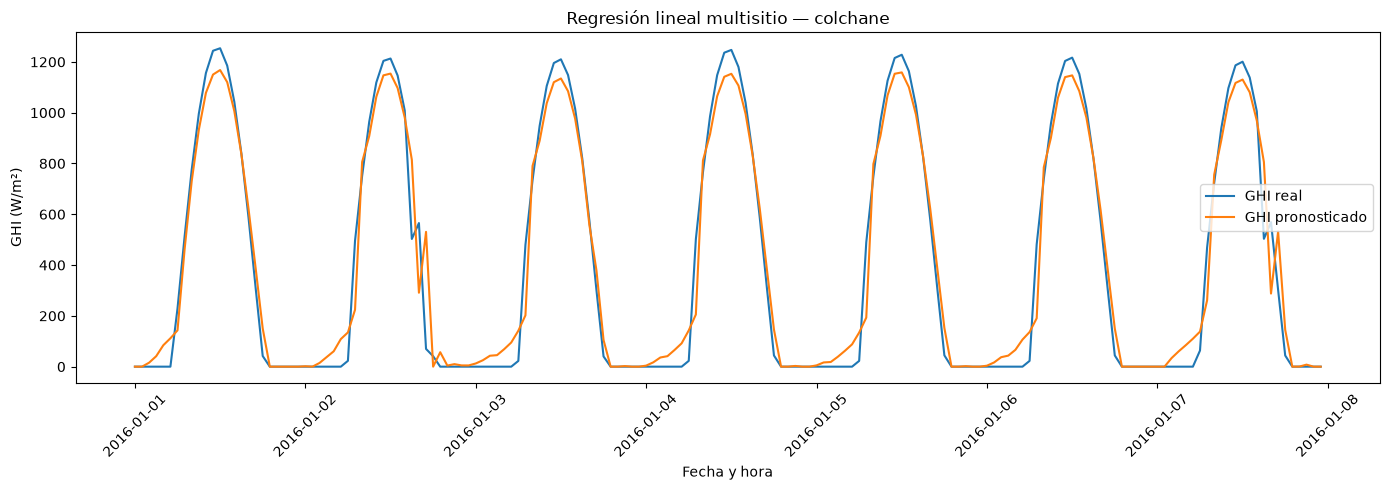

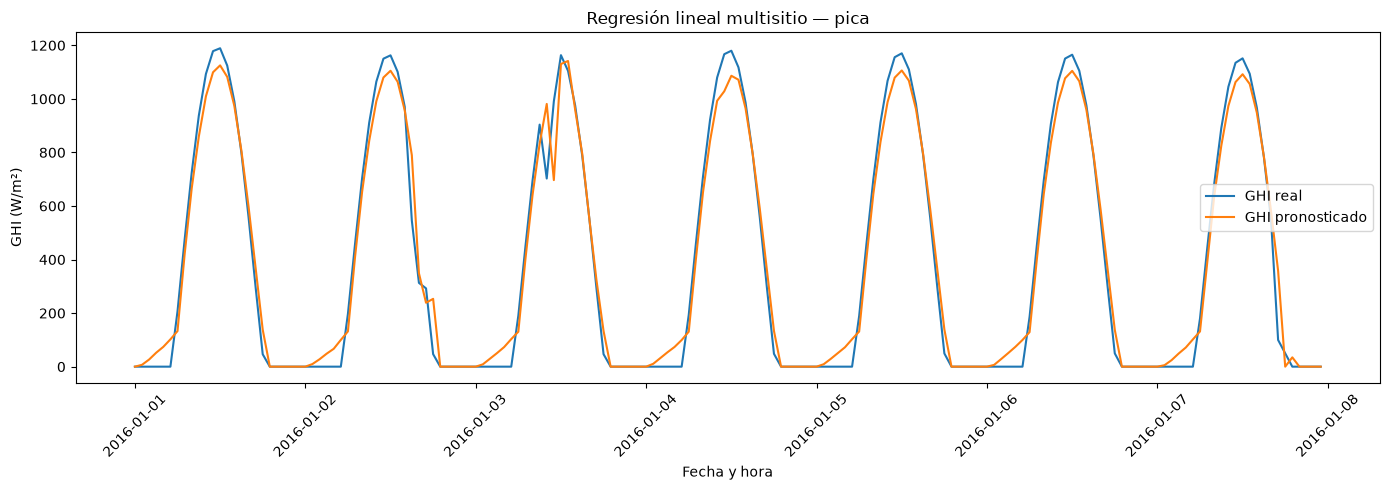

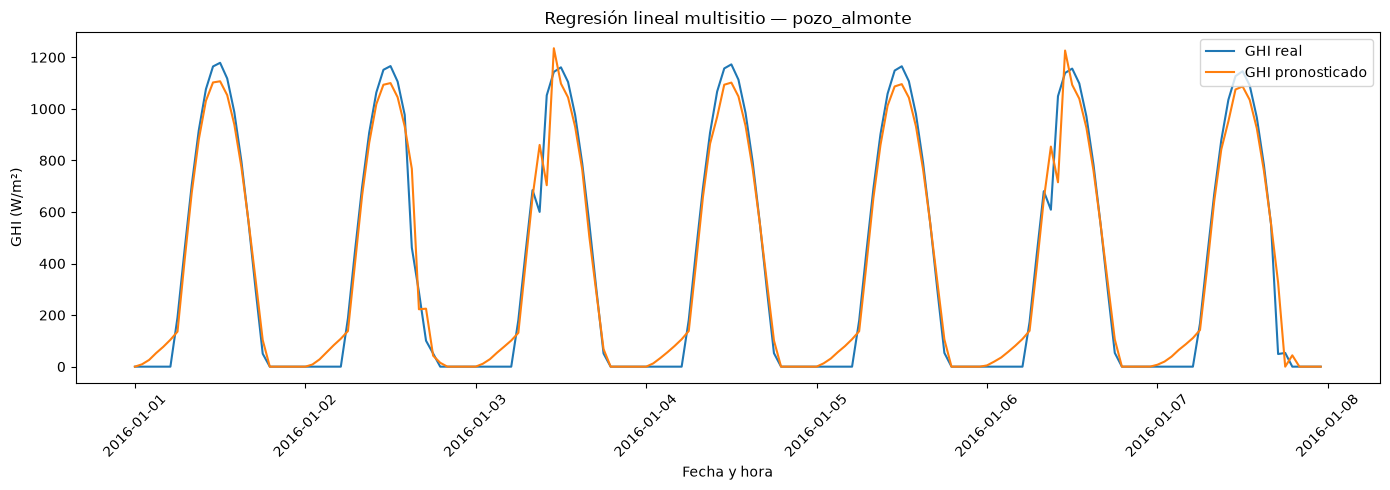

In [30]:
#graficar semana por columna
for comuna in resultados_test["comuna"].unique():

    muestra = (
        resultados_test[
            resultados_test["comuna"] == comuna
        ]
        .sort_values("fecha_hora")
        .head(24 * 7)
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        muestra["fecha_hora"],
        muestra[target],
        label="GHI real"
    )

    plt.plot(
        muestra["fecha_hora"],
        muestra["prediccion_ajustada"],
        label="GHI pronosticado"
    )

    plt.xlabel("Fecha y hora")
    plt.ylabel("GHI (W/m²)")
    plt.title(
        f"Regresión lineal multisitio — {comuna}"
    )

    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [31]:
#analizar residuos
residuos = (
    y_test.to_numpy()
    - pred_test
)

print("Media de residuos:", residuos.mean())
print("Desviación estándar:", residuos.std())

Media de residuos: -8.748230410687185
Desviación estándar: 79.5980239886405


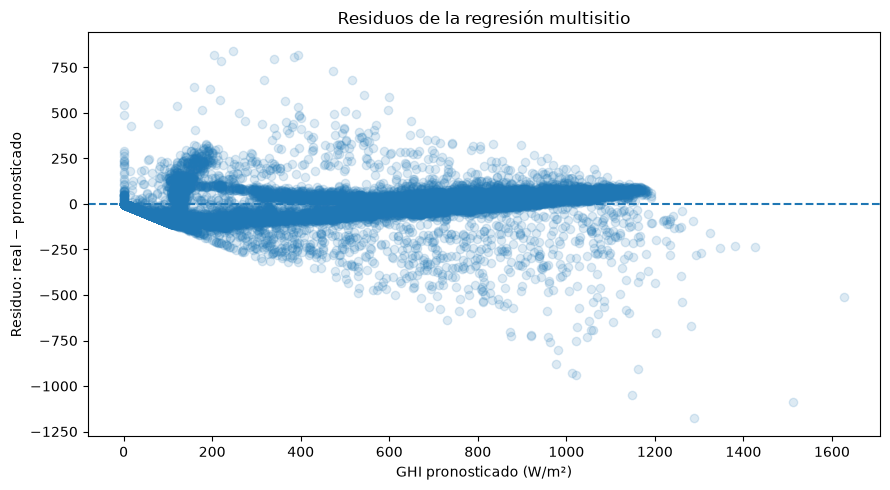

In [32]:
#graficar
plt.figure(figsize=(9, 5))

plt.scatter(
    pred_test,
    residuos,
    alpha=0.15
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("GHI pronosticado (W/m²)")
plt.ylabel("Residuo: real − pronosticado")
plt.title("Residuos de la regresión multisitio")
plt.tight_layout()
plt.show()

In [33]:
import joblib

# Directorios de salida
MODELS_DIR = PROJECT_DIR / "models"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
PREDICTIONS_DIR = PROJECT_DIR / "results" / "predictions"

for carpeta in [MODELS_DIR, METRICS_DIR, PREDICTIONS_DIR]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Guardar modelo entrenado
joblib.dump(
    modelo_regresion_final,
    MODELS_DIR / "regresion_lineal.joblib"
)

# Guardar predicciones en prueba
resultados_test.to_csv(
    PREDICTIONS_DIR / "regresion_lineal_prueba.csv",
    index=False
)

# Guardar métricas por localidad
metricas_comuna.to_csv(
    METRICS_DIR / "regresion_lineal_localidades.csv",
    index=False
)

print("Modelo y resultados guardados correctamente.")


Modelo y resultados guardados correctamente.
